# Projet 2 – Classification des fèves de cacao
## Étape 1 : Exploration du jeu de données
Objectif : comprendre l'organisation du dataset, le nombre d'images par classe et la qualité des images.

In [ ]:
#les bibliothèques
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
#Trouvons les classes 
DATA_DIR = "../data/feve"

classes = sorted(os.listdir(DATA_DIR))
classes = [c for c in classes if not c.startswith(".")]
print("Classes trouvées :", classes)

Classes trouvées : ['category 1', 'category 2', 'category 3']


In [3]:
#Compter les images par classe

comptage = {}
for c in classes:
    fichiers = os.listdir(os.path.join(DATA_DIR, c))
    comptage[c] = len([f for f in fichiers if f.endswith(".jpg")])

df_comptage = pd.DataFrame(list(comptage.items()), columns=["Classe", "Nombre d'images"])
df_comptage["Pourcentage (%)"] = (df_comptage["Nombre d'images"] / df_comptage["Nombre d'images"].sum() * 100).round(1)
df_comptage

,Classe,Nombre d'images,Pourcentage (%)
0,category 1,1917,42.9
1,category 2,1675,37.5
2,category 3,878,19.6


**Observation :** le dataset contient 4 470 images réparties en trois classes.
Les classes ne sont pas équilibrées : la Category 1 a environ 2,2 fois plus d'images que la Category 3 (1 917 contre 878).
Un modèle risque donc de favoriser les classes majoritaires. Pour l'évaluation, on utilisera des métriques en moyenne macro (Precision, Recall, F1), qui donnent le même poids aux trois classes.

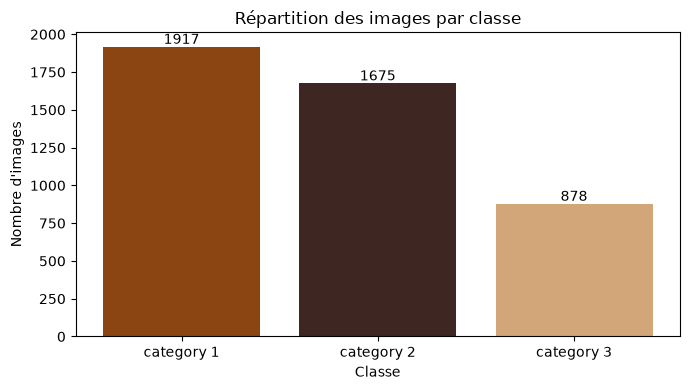

In [4]:
#visualiser la répartition. Un graphique en barres se lit plus vite qu’un tableau dans le rapport.

plt.figure(figsize=(7, 4))
barres = plt.bar(df_comptage["Classe"], df_comptage["Nombre d'images"], color=["#8B4513", "#3E2723", "#D2A679"])

# Afficher le nombre au-dessus de chaque barre
for barre in barres:
    hauteur = barre.get_height()
    plt.text(barre.get_x() + barre.get_width() / 2, hauteur + 20, str(int(hauteur)), ha="center")

plt.title("Répartition des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.savefig("../results/figures/01_repartition_classes.png", dpi=150)
plt.show()

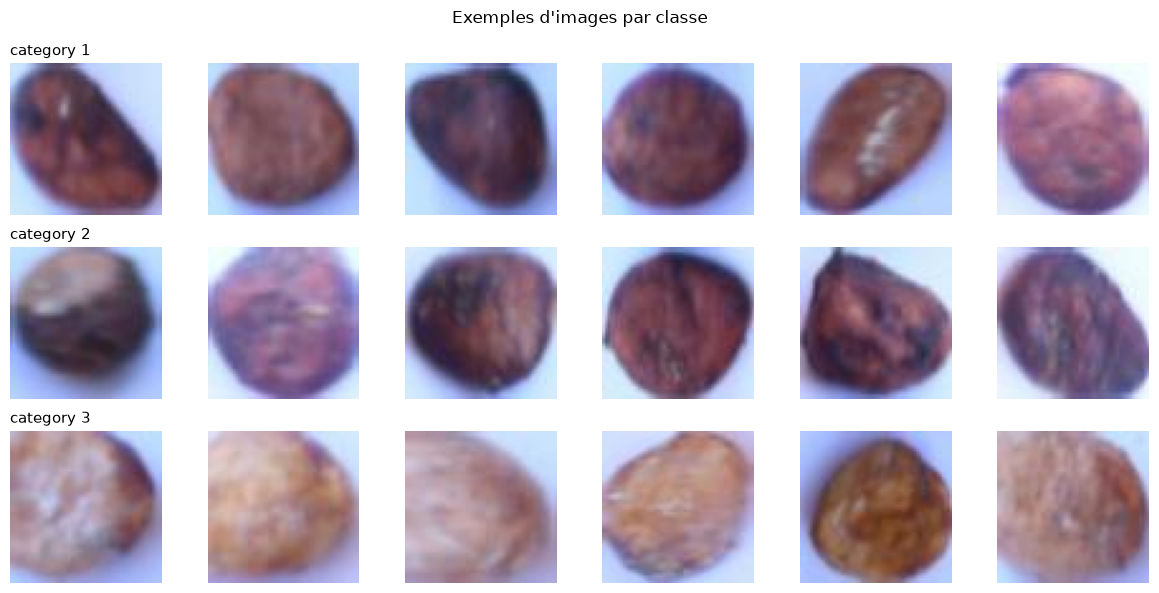

In [5]:
#Affichons des exemples de chaque classe

np.random.seed(42)
nb_exemples = 6

fig, axes = plt.subplots(len(classes), nb_exemples, figsize=(12, 6))

for i, c in enumerate(classes):
    dossier = os.path.join(DATA_DIR, c)
    fichiers = [f for f in os.listdir(dossier) if f.endswith(".jpg")]
    choix = np.random.choice(fichiers, nb_exemples, replace=False)

    for j, nom in enumerate(choix):
        img = Image.open(os.path.join(dossier, nom))
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=11)

plt.suptitle("Exemples d'images par classe")
plt.tight_layout()
plt.savefig("../results/figures/01_exemples_par_classe.png", dpi=150)
plt.show()

**Observations :**
- **Category 3** se distingue nettement : des fèves claires, beiges à brun doré, à la surface plus mate.
- **Category 1** et **Category 2** se ressemblent davantage : toutes deux brun-rouge à violacé. Les fèves de la Category 2 paraissent globalement plus sombres, avec des zones presque noires et une surface plus ridée.
- On peut donc s'attendre à ce que les modèles confondent surtout la Category 1 et la Category 2.
- Le fond est uniforme, bleu-lavande clair, et la fève occupe presque toute l'image. Cette teinte bleutée du fond devra être prise en compte dans l'analyse des couleurs.
- Les images sont petites (60 × 60 pixels) et un peu floues : les détails de texture fins seront limités.

In [6]:
#Contrôle qualité: On ouvre chaque image pour vérifier sa taille, son mode de couleur, et s’assurer qu’aucune n’est corrompue.

# Contrôle qualité : taille, mode de couleur et images corrompues
infos = []
corrompues = []

for c in classes:
    dossier = os.path.join(DATA_DIR, c)
    for nom in os.listdir(dossier):
        if not nom.endswith(".jpg"):
            continue
        chemin = os.path.join(dossier, nom)
        try:
            img = Image.open(chemin)
            img.verify()                  # vérifie que le fichier n'est pas abîmé
            img = Image.open(chemin)      # on le rouvre, car verify() le "consomme"
            infos.append({"classe": c, "fichier": nom, "largeur": img.size[0],
                          "hauteur": img.size[1], "mode": img.mode})
        except Exception:
            corrompues.append(chemin)

df_infos = pd.DataFrame(infos)
print("Nombre d'images lues :", len(df_infos))
print("Images corrompues :", len(corrompues))
print("\nTailles rencontrées :")
print(df_infos.groupby(["largeur", "hauteur"]).size())
print("\nModes de couleur :")
print(df_infos["mode"].value_counts())

Nombre d'images lues : 4470
Images corrompues : 0

Tailles rencontrées :
largeur  hauteur
60       60         4470
dtype: int64

Modes de couleur :
mode
RGB    4470
Name: count, dtype: int64


In [7]:
#doublons exacts. Deux fichiers parfaitement identiques ont la même « empreinte » (hash MD5) : c’est une signature calculée à partir du contenu du fichier.

import hashlib

# Calcul de l'empreinte MD5 de chaque image
def empreinte(chemin):
    with open(chemin, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df_infos["md5"] = [empreinte(os.path.join(DATA_DIR, c, f))
                   for c, f in zip(df_infos["classe"], df_infos["fichier"])]

doublons_exacts = df_infos[df_infos.duplicated("md5", keep=False)]
print("Nombre d'images en doublon exact :", len(doublons_exacts))

Nombre d'images en doublon exact : 0


**Qualité du dataset :** les 4 470 images sont lisibles (aucune image corrompue), toutes au format 60 × 60 pixels en RGB, et aucun fichier n'est un doublon exact. Le dataset est donc homogène et ne demande pas de nettoyage de format.

In [8]:
#Calcul des empreintes perceptuelles

# Empreinte perceptuelle de chaque image (16x16 pixels, niveaux de gris)
chemins = [os.path.join(DATA_DIR, c, f) for c, f in zip(df_infos["classe"], df_infos["fichier"])]

empreintes = []
for chemin in chemins:
    img = Image.open(chemin).convert("L").resize((16, 16))
    pixels = np.asarray(img, dtype=np.float32).ravel()
    empreintes.append(pixels > pixels.mean())

B = np.array(empreintes, dtype=np.float32)
print("Taille de la matrice des empreintes :", B.shape)

Taille de la matrice des empreintes : (4470, 256)


In [9]:
#comparer toutes les images entre elles. Le nombre de bits différents entre deux empreintes s’appelle la distance de Hamming. On la calcule pour toutes les paires d’un coup, grâce à un produit de matrices :

# Distance de Hamming entre toutes les paires d'images
distances = B @ (1 - B).T + (1 - B) @ B.T
np.fill_diagonal(distances, 999)   # on ignore la comparaison d'une image avec elle-même

SEUIL = 5   # au plus 5 bits différents sur 256 -> même fève
i_idx, j_idx = np.where(np.triu(distances <= SEUIL))
print("Nombre de paires de quasi-doublons :", len(i_idx))

paires_inter = sum(df_infos["classe"].iloc[i] != df_infos["classe"].iloc[j] for i, j in zip(i_idx, j_idx))
print("Dont paires entre deux classes différentes :", paires_inter)

Nombre de paires de quasi-doublons : 675
Dont paires entre deux classes différentes : 1


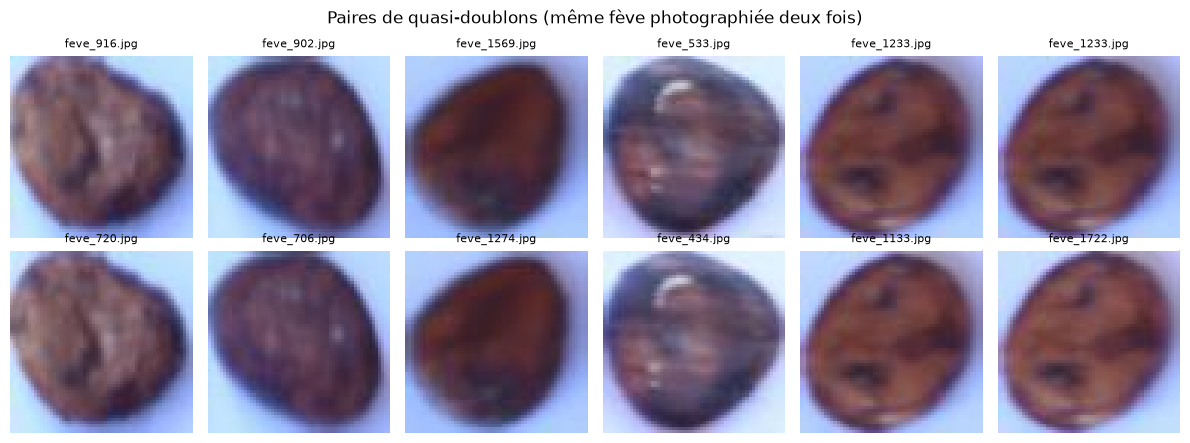

In [10]:
#Vérifier

# Afficher 6 paires de quasi-doublons côte à côte
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for k in range(6):
    a, b = i_idx[k], j_idx[k]
    for ligne, idx in enumerate([a, b]):
        axes[ligne, k].imshow(Image.open(chemins[idx]))
        axes[ligne, k].set_title(df_infos["fichier"].iloc[idx], fontsize=8)
        axes[ligne, k].axis("off")
plt.suptitle("Paires de quasi-doublons (même fève photographiée deux fois)")
plt.tight_layout()
plt.savefig("../results/figures/01_quasi_doublons.png", dpi=150)
plt.show()

In [11]:
#Former les groupes de fèves. On relie les images qui se ressemblent comme les points d’un graphe : si A ressemble à B et B à C, alors A, B et C forment un seul groupe, c’est-à-dire une seule fève. En théorie des graphes, ces groupes s’appellent des composantes connexes.

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# Chaque groupe = une fève physique (une ou plusieurs photos)
graphe = csr_matrix(distances <= SEUIL)
nb_groupes, etiquettes = connected_components(graphe, directed=False)
df_infos["groupe"] = etiquettes

taille_groupes = df_infos.groupby("groupe").size()
print("Nombre de fèves distinctes (groupes) :", nb_groupes)
print("\nNombre de groupes selon le nombre de photos :")
print(taille_groupes.value_counts().sort_index())
print("\nNombre de fèves distinctes par classe :")
print(df_infos.groupby("classe")["groupe"].nunique())

Nombre de fèves distinctes (groupes) : 3911

Nombre de groupes selon le nombre de photos :
1    3546
2     264
3      45
4      31
5      15
6       8
7       2
Name: count, dtype: int64

Nombre de fèves distinctes par classe :
classe
category 1    1524
category 2    1542
category 3     846
Name: groupe, dtype: int64


          classe        fichier  groupe
1784  category 1  feve_1375.jpg    1424
2944  category 2   feve_348.jpg    1424
3576  category 2   feve_502.jpg    1424


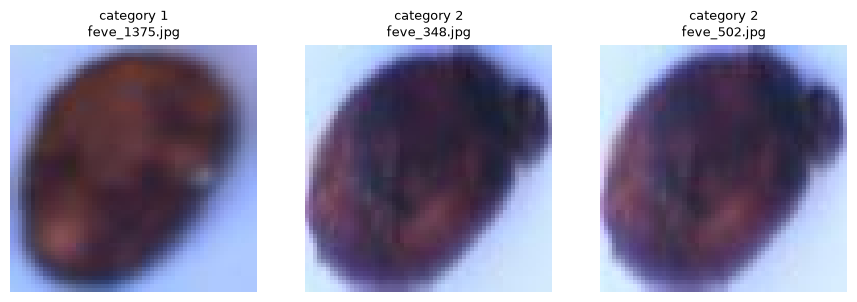

In [12]:
#Groupe qui mélange deux classes. La cellule 13 a trouvé une paire entre deux classes différentes. Regardons :

# Groupes contenant des images de classes différentes
classes_par_groupe = df_infos.groupby("groupe")["classe"].nunique()
groupes_mixtes = classes_par_groupe[classes_par_groupe > 1].index
cas_mixtes = df_infos[df_infos["groupe"].isin(groupes_mixtes)]
print(cas_mixtes[["classe", "fichier", "groupe"]])

fig, axes = plt.subplots(1, len(cas_mixtes), figsize=(3 * len(cas_mixtes), 3))
for ax, (_, ligne) in zip(axes, cas_mixtes.iterrows()):
    ax.imshow(Image.open(os.path.join(DATA_DIR, ligne["classe"], ligne["fichier"])))
    ax.set_title(f"{ligne['classe']}\n{ligne['fichier']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../results/figures/01_groupe_mixte.png", dpi=150)
plt.show()

In [13]:
# Sauvegarde de l'inventaire complet (avec les groupes)
df_infos[["classe", "fichier", "largeur", "hauteur", "mode", "md5", "groupe"]].to_csv(
    "../results/tables/01_inventaire_images.csv", index=False)
print("Inventaire sauvegardé :", len(df_infos), "images")

Inventaire sauvegardé : 4470 images


In [14]:
# Influence du seuil sur la détection des groupes
resultats_seuil = []
for s in range(3, 10):
    n, etiq = connected_components(csr_matrix(distances <= s), directed=False)
    tailles = pd.Series(etiq).value_counts()
    i_s, j_s = np.where(np.triu(distances <= s))
    inter = sum(df_infos["classe"].iloc[a] != df_infos["classe"].iloc[b] for a, b in zip(i_s, j_s))
    resultats_seuil.append({"seuil": s, "paires": len(i_s), "groupes": n,
                            "taille max d'un groupe": tailles.max(), "paires entre classes": inter})

df_seuil = pd.DataFrame(resultats_seuil)
df_seuil.to_csv("../results/tables/01_choix_seuil.csv", index=False)
df_seuil

,seuil,paires,groupes,taille max d'un groupe,paires entre classes
0,3,232,4254,4,0
1,4,438,4085,6,0
2,5,675,3911,7,1
3,6,1008,3681,17,3
4,7,1428,3399,88,23
5,8,1894,3187,110,40
6,9,2502,2922,137,69


**Choix du seuil :** au-delà de 5 bits, les groupes s'enchaînent artificiellement (un groupe de 88 images à 7 bits, ce qui n'a pas de sens physique) et les paires entre classes différentes augmentent rapidement. Le seuil de 5 est donc un choix **prudent** : les groupes détectés sont fiables (7 photos au maximum par fève), mais certaines re-photographies d'une même fève peuvent ne pas être détectées. Une petite fuite résiduelle entre entraînement et test reste possible ; elle sera mentionnée dans les limites du projet.

**Groupe mixte :** un seul groupe contient des images de deux classes. Après vérification visuelle, `feve_348` et `feve_502` (Category 2) sont bien la même fève photographiée deux fois, tandis que `feve_1375` (Category 1) est une fève différente, de silhouette et d'orientation proches mais plus rouge et plus lisse. Il ne s'agit donc pas d'une erreur d'étiquetage, mais d'un faux positif de l'empreinte perceptuelle, qui ne voit que la forme générale en niveaux de gris. Ce groupe est conservé tel quel : regrouper ces trois images est sans conséquence pour la séparation des données.

## Conclusion de l'étape 1

- Le dataset contient **4 470 images** de 60 × 60 pixels en RGB, réparties en trois classes **déséquilibrées** (42,9 % / 37,5 % / 19,6 %). → On utilisera des métriques en moyenne macro et une pondération des classes.
- Aucune image n'est corrompue et il n'y a **aucun doublon exact**.
- En revanche, **675 paires de quasi-doublons** ont été détectées : une même fève a souvent été photographiée plusieurs fois (jusqu'à 7 fois). Les 4 470 images correspondent à environ **3 911 fèves distinctes**.
- Si l'on séparait les images au hasard, des photos d'une même fève se retrouveraient à la fois dans l'entraînement et dans le test, ce qui gonflerait artificiellement les performances. → À l'étape 2, la séparation se fera **par groupe de fèves**.
- Visuellement, la **Category 3** (fèves claires) se distingue bien, alors que les **Categories 1 et 2** sont proches. On s'attend à ce que la plupart des erreurs de classification se produisent entre elles.
- L'inventaire avec les groupes est enregistré dans `results/tables/01_inventaire_images.csv`.